## Лабораторная работа №2
### Факторный анализ. Метод главных компонент
##### Задачи исследования

1. Применить факторный анализ (метод главных компонет) к совокупности анализируемых данных. Проанализировать целесообразность использования данного метода анализа на основе специальных критериев и тестовых статистик.
2. На основании результатов факторного анализа определить наиболее значимые коэффициенты, сохраняющие наибольший процент дисперсии исходных показателей.
3. Рассчитать интегральный показатель кредитоспособности как взвешенную сумму полученных главных компонент. В качестве весов использовать соответствующие величины процентов объясненной дисперсии.
---

In [22]:
import pandas as pd
import numpy as np
import pyreadstat
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.manifold import TSNE, Isomap, trustworthiness
from sklearn.model_selection import GridSearchCV
import umap

data_path = '../Lab1/data_prepared.sav'
data, meta = pyreadstat.read_sav(data_path)
data = data.drop(columns = ['Cреднеспис.числ.работн', 'Year', 'k8', 'k4_new'])

display(data.head())

,k1,k2,k3,k4,k5,k6,k7,k9,k10,k11,k12,k13,k14,k15,k16,k17,k18,k19,k20
0,-0.844835,-0.462730,-0.072648,-0.598994,-0.751148,-0.331432,1.278778,-0.146335,-1.082426,-0.557283,-0.577876,-0.835996,-0.825805,-1.047613,-0.607049,2.602140,0.211227,-0.243578,-0.328480
1,0.157523,0.455945,0.365043,1.203309,-1.370943,-0.037174,-0.855084,1.748623,-1.070642,-0.097657,-0.465682,-0.753145,0.213520,0.029907,-0.432844,2.602140,0.779055,-0.182741,-0.426828
2,-1.393485,-0.716524,-1.161337,-1.910963,-0.565866,1.487737,2.129474,-0.236418,-1.309145,-1.650874,-0.297390,-1.718144,-1.442924,-0.751906,2.389905,-0.086135,-2.270520,-0.820572,-0.699316
3,2.332474,2.562626,2.294498,1.779887,-1.535617,-1.045480,-0.795666,2.233061,0.262642,-0.213310,0.041887,1.810148,1.973667,1.823270,-0.837995,-0.153880,1.582677,2.020363,2.113090
4,-0.036668,-0.698900,0.303591,0.981855,-1.117287,1.929763,1.764138,0.982473,-0.872526,-1.331145,-0.818413,-1.138972,-0.627855,-1.157741,-0.828347,-0.460696,0.038988,-0.623905,-0.573538


Был исключен коэффицент k8, так как из предыдущей работы мы знаем, что он имеете сильную отрицательную корреляцию с k5. И был исключен коэффицент k4_new, так как есть столбец k4 без пропусков

Для оценки целесообразности применения факторного анализа для конкретной выборки данных используются специальные критерии и тестовые статистики, которые позволяют исследовать требуемые свойства выборочной корреляционной матрицы. В рамках проводимого анализа используются: критерий сферичности Бартлетта и статистика Кайзера−Мейера−Олкина (КМО).

### Критерий сферичности Бартлетта

$$
\chi^2 = -\left(n - 1 - \frac{2p + 5}{6}\right) \cdot \ln |R|
$$

Где:
- $\chi^2$ — вычисляемое значение статистики Хи-квадрат.
- $n$ — объем выборки (количество наблюдений/строк в данных).
- $p$ — количество исходных переменных (столбцов).
- $|R|$ — определитель (детерминант) корреляционной матрицы исходных данных.

Нулевая гипотеза $H_0$: корреляционная матрица является единичной.

---

### Статистика Кайзера–Мейера–Олкина

$$
KMO = \frac{\sum_{i \neq j} r_{ij}^2}{\sum_{i \neq j} r_{ij}^2 + \sum_{i \neq j} a_{ij}^2}
$$

Где:
- $r_{ij}$ — парный (обычный) коэффициент корреляции Пирсона между переменной $i$ и переменной $j$.
- $a_{ij}$ — коэффициент частной корреляции между переменной $i$ и переменной $j$ при исключении влияния всех остальных переменных модели.

Частным (условным) коэффициентом корреляции непрерывных случайных величин $X$ и $Y$ при условии, что значение $Z$ фиксировано (влияние $Z$ «вычтено»), называется характеристика:

$$
\rho_{X,Y|Z} = \frac{\rho_{X,Y} - \rho_{X,Z}\rho_{Y,Z}}{\sqrt{(1 - \rho_{X,Z}^2)(1 - \rho_{Y,Z}^2)}} \in [-1, 1]
$$

Где:
- $\rho_{X,Y}$, $\rho_{X,Z}$, $\rho_{Y,Z}$ — обычные парные коэффициенты корреляции Пирсона между соответствующими парами переменных.

In [23]:
chi_square_value, p_value = calculate_bartlett_sphericity(data)
kmo_all, kmo_model = calculate_kmo(data)

print(f"Статистика Хи-квадрат Бартлетт: {chi_square_value}")
print(f"p-value Бартлетт: {p_value}")
print(f"Общий индекс KMO: {kmo_model}")

Статистика Хи-квадрат Бартлетт: 41436.558886580344
p-value Бартлетт: 0.0
Общий индекс KMO: 0.7330787557354004


То что матрица является единичной отклоняется в соответствии с критерием Бартлетта. А значение статистики КМО 0.733 говорит о приемлем качестве выборки для применения факторного анализа

In [24]:
pca = PCA()
pca.fit(data)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [25]:
variance_df = pd.DataFrame({
    'Собственное значение': pca.explained_variance_,
    'Доля дисперсии': pca.explained_variance_ratio_ * 100,
    'Накопленная дисперсия': np.cumsum(pca.explained_variance_ratio_) * 100
})

variance_df.index = [f'PC{i+1}' for i in range(len(variance_df))]

display(variance_df)

,Собственное значение,Доля дисперсии,Накопленная дисперсия
PC1,6.033273,31.742286,31.742286
PC2,2.856207,15.027091,46.769376
PC3,1.928004,10.143622,56.912998
PC4,1.586778,8.348367,65.261365
PC5,1.211399,6.373417,71.634782
PC6,1.101557,5.795518,77.430300
PC7,0.832084,4.377765,81.808065
PC8,0.691999,3.640749,85.448814
PC9,0.564847,2.971774,88.420588
PC10,0.537550,2.828162,91.248750


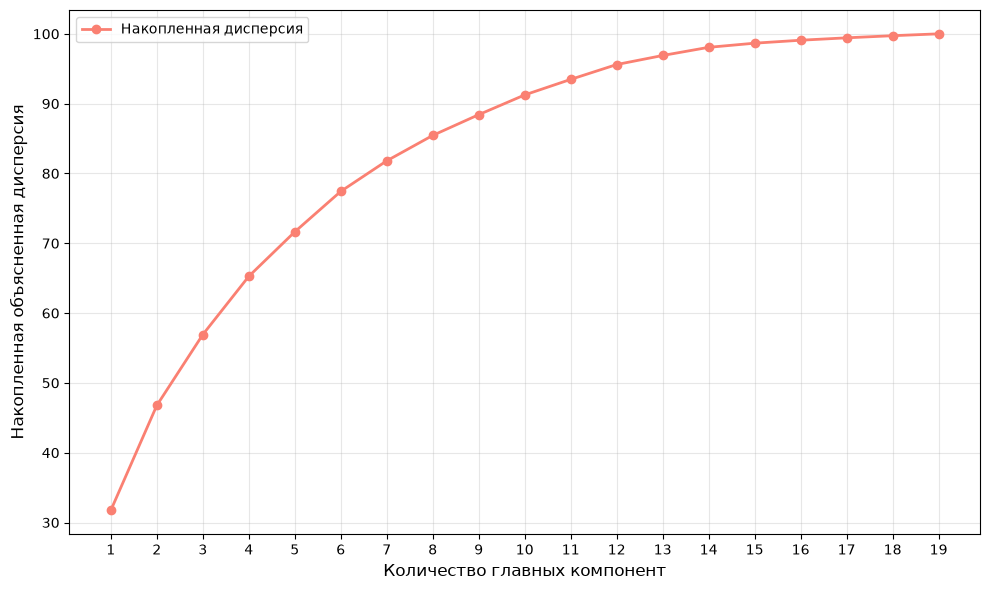

In [26]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), 
         cumulative_variance, marker = 'o', linestyle = '-', color = 'salmon', linewidth = 2, label = 'Накопленная дисперсия')

plt.xlabel('Количество главных компонент', fontsize = 12)
plt.ylabel('Накопленная объясненная дисперсия', fontsize = 12)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

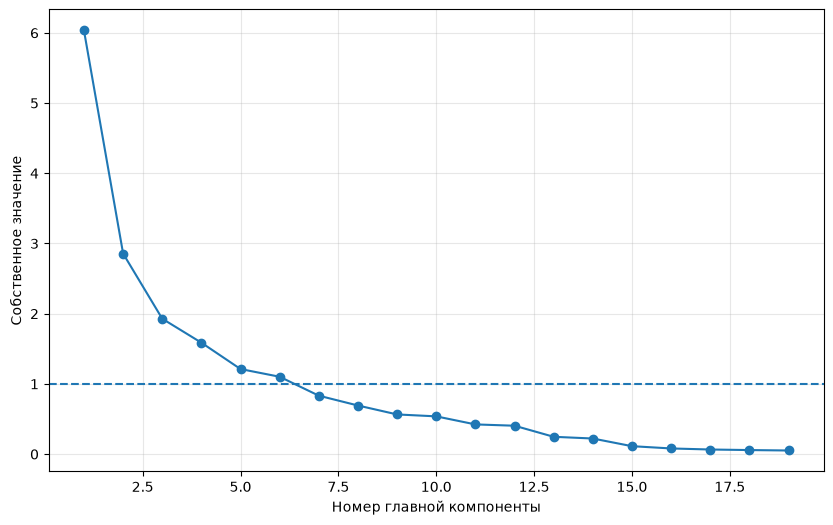

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_) + 1), pca.explained_variance_, marker = 'o')
plt.axhline(y = 1, linestyle = '--')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Собственное значение')
plt.grid(alpha=0.3)
plt.show()

По правилу кайзера стоит брать компоеннты у которых собственные значения больше 1. Это первые 6 компнент.

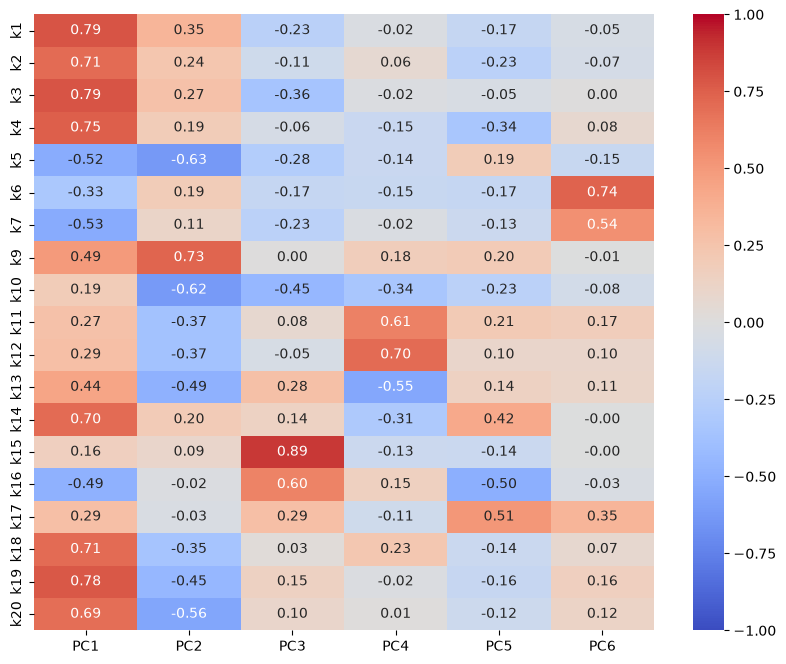

In [28]:
factor_weights = pca.components_.T * np.sqrt(pca.explained_variance_)
pca_res = pd.DataFrame(factor_weights, columns = [f"PC{i+1}" for i in range(pca.n_components_)], index = data.columns)

plt.figure(figsize = (10, 8))
sns.heatmap(pca_res.iloc[:, :6], annot = True, fmt = '.2f', vmin = -1, vmax = 1, cmap = 'coolwarm')
plt.show()

- Можно заметить, что PC1 содержит в себе информацию о коэффицентах k1 - k4, k14, k18- k20. Также есть и значительная обратная связь с коэффицентами k5, k7, k16
- В PC2 выделяется k9, но и много обратных связей k10, k13, k20.
- В PC3 очень сильная связть с k15

Но также мы можем заметить, что многие коэффиценты размазались по нескольким факторам


In [29]:
fa = FactorAnalysis(n_components=6, rotation='quartimax')
fa.fit(data)

,"n_components n_components: int, default=NoneDimensionality of latent space, the number of componentsof ``X`` that are obtained after ``transform``.If None, n_components is set to the number of features.",6
,"rotation rotation: {'varimax', 'quartimax'}, default=NoneIf not None, apply the indicated rotation. Currently, varimax andquartimax are implemented. See`""The varimax criterion for analytic rotation in factor analysis""<https://link.springer.com/article/10.1007%2FBF02289233>`_H. F. Kaiser, 1958... versionadded:: 0.24",'quartimax'
,"tol tol: float, default=1e-2Stopping tolerance for log-likelihood increase.",0.01
,"copy copy: bool, default=TrueWhether to make a copy of X. If ``False``, the input X gets overwrittenduring fitting.",True
,"max_iter max_iter: int, default=1000Maximum number of iterations.",1000
,"noise_variance_init noise_variance_init: array-like of shape (n_features,), default=NoneThe initial guess of the noise variance for each feature.If None, it defaults to np.ones(n_features).",None
,"svd_method svd_method: {'lapack', 'randomized'}, default='randomized'Which SVD method to use. If 'lapack' use standard SVD fromscipy.linalg, if 'randomized' use fast ``randomized_svd`` function.Defaults to 'randomized'. For most applications 'randomized' willbe sufficiently precise while providing significant speed gains.Accuracy can also be improved by setting higher values for`iterated_power`. If this is not sufficient, for maximum precisionyou should choose 'lapack'.",'randomized'
,"iterated_power iterated_power: int, default=3Number of iterations for the power method. 3 by default. Only usedif ``svd_method`` equals 'randomized'.",3
,"random_state random_state: int or RandomState instance, default=0Only used when ``svd_method`` equals 'randomized'. Pass an int forreproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
Name,Type,Value
"components_ components_: ndarray of shape (n_components, n_features)Components with maximum variance.","ndarray[float64](6, 19)","[[ 0.16, 0.03, 0.08,..., 0.06, 0.08,-0.05], [ 0.19, 0.21, 0.21,..., 0.75, 0.92, 0.94], [-0.02, 0.12,-0.2 ,...,-0.02, 0.05,-0. ], [ 0.16, 0.01, 0.1 ,..., 0.06, 0.03, 0.04], [-0.01,-0.05, 0.05,...,-0.07, 0.18, 0.13], [-0.87,-0.82,-0.91,...,-0.26,-0.26,-0.15]]"


Выбор метода Quartimax обусловлен тем, что он применяется обычно при наличии доминирующего фактора. При применении PCA мы заметили, что PC1 объясняет около 31% дисперсии, что в два раза больше чем PC2

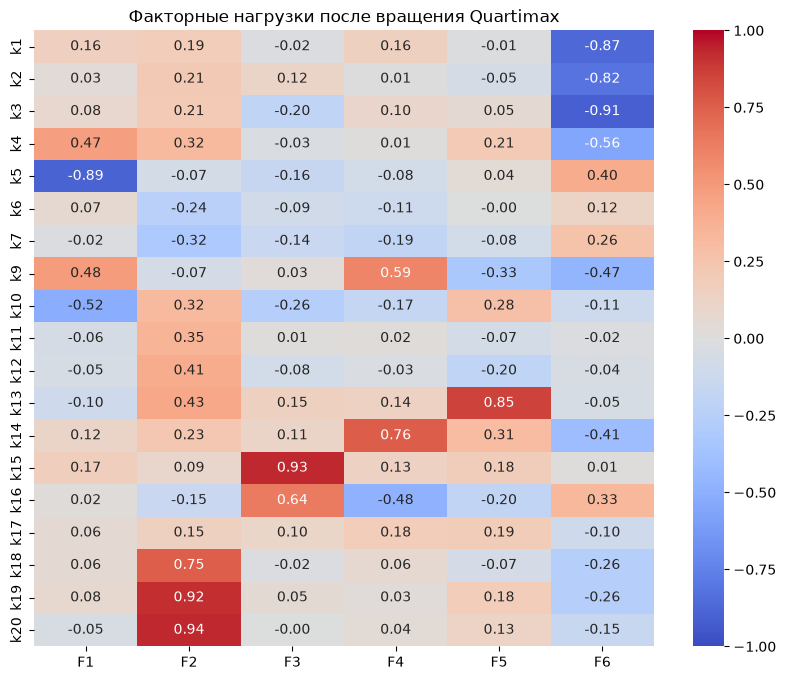

In [30]:
fa_res = pd.DataFrame(
    fa.components_.T,
    columns=[f"F{i+1}" for i in range(6)],
    index=data.columns
)

plt.figure(figsize=(10, 8))
sns.heatmap(fa_res, annot = True, fmt = '.2f', vmin = -1, vmax = 1, cmap = 'coolwarm')
plt.title('Факторные нагрузки после вращения Quartimax')
plt.show()

Теперь после применения факторного анализа с вращением можно заметить, что данные стали менее размазанными по компонентам и можно охарактеризовать каждую из них

3. Интегральный показатель

Вычисление значений интегрального (сводного) показателя по формуле:

$$
I_i = \delta_1 f_{1i} + \delta_2 f_{2i} + \dots + \delta_k f_{ki}, \quad i = 1, \dots, n
$$

где весовой коэффициент $\delta_k$ выражает относительный вклад $k$-й главной компоненты в общую дисперсию и вычисляется по формуле:

$$
\delta_k = \frac{\lambda_k}{\sum_{j=1}^N \lambda_j}, \quad k = 1, \dots, K
$$

Где:
* $I_i$ — значение интегрального показателя для $i$-го объекта;
* $f_{ki}$ — значение $k$-й главной компоненты для $i$-го объекта;
* $\delta_k$ — вес (относительный вклад) $k$-й главной компоненты;
* $\lambda_k$ — собственное значение (дисперсия) $k$-й главной компоненты;
* $N$ — количество отобранных главных компонент ($N = 6$).

In [ ]:

pca_scores = pd.DataFrame(pca.transform(data), 
                          columns = [f"PC{i + 1}" for i in range(pca.n_components_)], 
                          index = data.index) 

weights = pca.explained_variance_[:6] / pca.explained_variance_[:6].sum()
integral_indicator = (weights * pca_scores.iloc[:, :6]).sum(axis = 1)

pca_scores['P'] = integral_indicator
display(pca_scores)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,P
0,-1.069851,0.764304,-0.144508,0.265328,1.465504,1.243932,0.669148,2.791916,-0.003011,1.010681,-0.353836,-0.269704,0.268217,-0.222248,-0.163342,-0.107700,-0.155538,-0.261028,-0.199146,-0.051755
1,1.713051,2.240685,0.781453,0.420853,1.206337,0.581355,0.564892,1.937842,1.229959,-0.249744,-0.421846,0.683303,0.173624,-0.464870,-0.097581,-0.015496,0.219583,0.245738,0.236212,1.105451
2,-4.884447,1.716277,0.468013,0.493326,-1.002294,1.369316,0.365094,1.086035,-1.006467,-0.036684,0.800879,-0.715006,-1.441700,0.106239,0.815407,-0.093195,-0.500198,-0.147066,-0.288534,-1.188392
3,6.707920,0.981797,0.929970,-0.944655,-0.878295,-0.320170,-0.177129,-0.633217,-1.327155,0.320497,0.240536,0.085326,-0.168356,-0.237964,-0.272030,-0.681664,0.227805,0.519399,0.057053,2.217719
4,-1.024964,2.576819,-1.706241,-0.302773,-0.748789,1.924280,-1.439314,1.022431,0.158907,0.083559,-0.018523,-0.074454,0.289121,-0.098923,-0.109807,-0.100018,0.453076,0.054992,0.113530,-0.072679
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2690,2.518257,-1.436247,-0.758406,0.358005,-0.758467,0.620710,-0.822696,0.435774,0.177871,-0.454690,-0.330674,-1.019470,0.082980,0.424162,0.093803,-0.133516,0.007150,-0.322204,0.442582,0.524117
2691,1.295704,-0.127027,0.200863,1.818810,0.735622,0.015869,-0.665078,-0.896134,0.753054,-0.149412,1.046682,-1.354089,0.188641,-0.283148,0.263716,-0.126219,0.225230,-0.287854,0.013463,0.612217
2692,1.428661,-1.064583,1.487585,0.170720,0.859477,2.391862,-0.880160,-0.687183,-0.017171,0.823370,1.703581,-1.012488,0.240425,-0.040714,0.147208,0.197893,-0.292776,-0.449098,0.530064,0.652060
2693,-0.049438,-0.880557,2.232356,1.735052,0.542965,-0.064119,-0.327380,-1.355755,0.841005,0.146277,1.247636,-0.599724,0.311138,0.079882,-0.275994,-0.182781,0.034418,-0.138141,-0.019014,0.254165


In [32]:
def calc_trustworthiness(estimator, features, target = None):
    coords = estimator.fit_transform(features)
    return trustworthiness(features, coords, n_neighbors = 5)

tsne = TSNE(n_components = 2)
parameter_grid = {
    'perplexity': [5, 10, 15, 20, 25, 30, 40, 50],
}

grid_search = GridSearchCV(estimator = tsne, param_grid = parameter_grid, scoring = calc_trustworthiness, refit = False,verbose = 2,)
grid_search.fit(data)

results_table = pd.DataFrame(grid_search.cv_results_)[[
    'param_perplexity',
    'mean_test_score',
    'std_test_score',
    'rank_test_score',
]].sort_values('rank_test_score')

display(results_table)

print(f"Лучшая perplexity: {grid_search.best_params_['perplexity']}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END .......................................perplexity=5; total time=   3.3s
[CV] END .......................................perplexity=5; total time=   3.4s
[CV] END .......................................perplexity=5; total time=   3.6s
[CV] END .......................................perplexity=5; total time=   8.0s
[CV] END .......................................perplexity=5; total time=   6.6s
[CV] END ......................................perplexity=10; total time=   3.8s
[CV] END ......................................perplexity=10; total time=   3.8s
[CV] END ......................................perplexity=10; total time=   4.1s
[CV] END ......................................perplexity=10; total time=   3.8s
[CV] END ......................................perplexity=10; total time=   3.8s
[CV] END ......................................perplexity=15; total time=   4.3s
[CV] END ......................................pe

,param_perplexity,mean_test_score,std_test_score,rank_test_score
2,15,0.973377,0.001712,1
1,10,0.973305,0.004676,2
4,25,0.972077,0.002373,3
3,20,0.971250,0.001895,4
0,5,0.970012,0.003069,5
5,30,0.969068,0.003244,6
6,40,0.967947,0.003320,7
7,50,0.966963,0.001976,8


Лучшая perplexity: 15


In [33]:
umap_model = umap.UMAP(n_components = 2)

parameter_grid_umap = {
    'n_neighbors': [5, 10, 30, 50],
    'min_dist': [0.0, 0.3, 0.5]
}

grid_search_umap = GridSearchCV(
    estimator = umap_model,
    param_grid = parameter_grid_umap,
    scoring = calc_trustworthiness,
    refit = False,
    verbose = 2,
)

grid_search_umap.fit(data)

results_umap = pd.DataFrame(grid_search_umap.cv_results_)[[
    'param_n_neighbors',
    'param_min_dist',
    'mean_test_score',
    'std_test_score',
    'rank_test_score',
]].sort_values('rank_test_score')

display(results_umap)

print(f"Лучшие параметры UMAP: {grid_search_umap.best_params_}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END ........................min_dist=0.0, n_neighbors=5; total time=   6.6s
[CV] END ........................min_dist=0.0, n_neighbors=5; total time=  12.6s
[CV] END ........................min_dist=0.0, n_neighbors=5; total time=  11.7s
[CV] END ........................min_dist=0.0, n_neighbors=5; total time=  12.9s
[CV] END ........................min_dist=0.0, n_neighbors=5; total time=  12.8s
[CV] END .......................min_dist=0.0, n_neighbors=10; total time=  13.3s
[CV] END .......................min_dist=0.0, n_neighbors=10; total time=  13.1s
[CV] END .......................min_dist=0.0, n_neighbors=10; total time=  12.3s
[CV] END .......................min_dist=0.0, n_neighbors=10; total time=  12.1s
[CV] END .......................min_dist=0.0, n_neighbors=10; total time=  12.9s
[CV] END .......................min_dist=0.0, n_neighbors=30; total time=   5.9s
[CV] END .......................min_dist=0.0, n_

,param_n_neighbors,param_min_dist,mean_test_score,std_test_score,rank_test_score
0,5,0.0,0.963685,0.003846,1
1,10,0.0,0.960273,0.003832,2
4,5,0.3,0.948064,0.003852,3
2,30,0.0,0.938869,0.006859,4
3,50,0.0,0.933474,0.004252,5
5,10,0.3,0.930338,0.008779,6
8,5,0.5,0.928223,0.010766,7
9,10,0.5,0.917180,0.009792,8
6,30,0.3,0.910052,0.006406,9
7,50,0.3,0.902570,0.008979,10


Лучшие параметры UMAP: {'min_dist': 0.0, 'n_neighbors': 5}


In [34]:
isomap_model = Isomap(n_components = 2)

parameter_grid_isomap = {
    'n_neighbors': [5, 10, 15, 20, 25, 30, 35, 50],
}

grid_search_isomap = GridSearchCV(
    estimator = isomap_model,
    param_grid = parameter_grid_isomap,
    scoring = calc_trustworthiness,
    refit = False,
    verbose = 2,
)

grid_search_isomap.fit(data)

results_isomap = pd.DataFrame(grid_search_isomap.cv_results_)[[
    'param_n_neighbors',
    'mean_test_score',
    'std_test_score',
    'rank_test_score',
]].sort_values('rank_test_score')

display(results_isomap)

print(f"Лучшие параметры Isomap: {grid_search_isomap.best_params_['n_neighbors']}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END ......................................n_neighbors=5; total time=   0.7s
[CV] END ......................................n_neighbors=5; total time=   0.6s
[CV] END ......................................n_neighbors=5; total time=   0.7s
[CV] END ......................................n_neighbors=5; total time=   1.3s
[CV] END ......................................n_neighbors=5; total time=   1.6s
[CV] END .....................................n_neighbors=10; total time=   2.0s
[CV] END .....................................n_neighbors=10; total time=   1.8s
[CV] END .....................................n_neighbors=10; total time=   1.8s
[CV] END .....................................n_neighbors=10; total time=   1.8s
[CV] END .....................................n_neighbors=10; total time=   1.7s
[CV] END .....................................n_neighbors=15; total time=   2.1s
[CV] END .....................................n_n

,param_n_neighbors,mean_test_score,std_test_score,rank_test_score
5,30,0.838141,0.017507,1
7,50,0.837430,0.014868,2
2,15,0.837424,0.016346,3
4,25,0.836849,0.016914,4
3,20,0.836848,0.014414,5
6,35,0.836699,0.016046,6
1,10,0.833481,0.014994,7
0,5,0.825129,0.014676,8


Лучшие параметры Isomap: 30


PCA(2): 0.8231515031834028
PCA(6): 0.9843496309103199
t-SNE: 0.988555685900574
Umap: 0.9790287738737948
Isomap: 0.8257222813339566


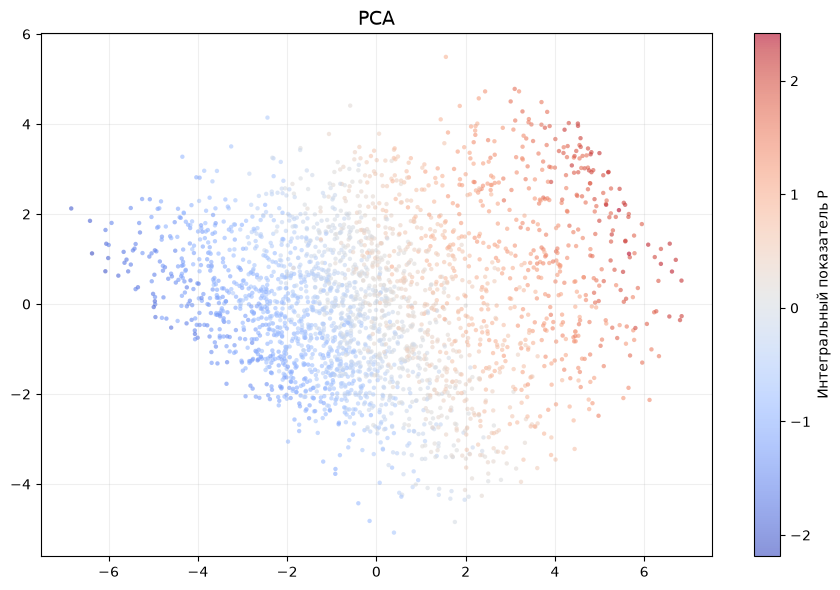

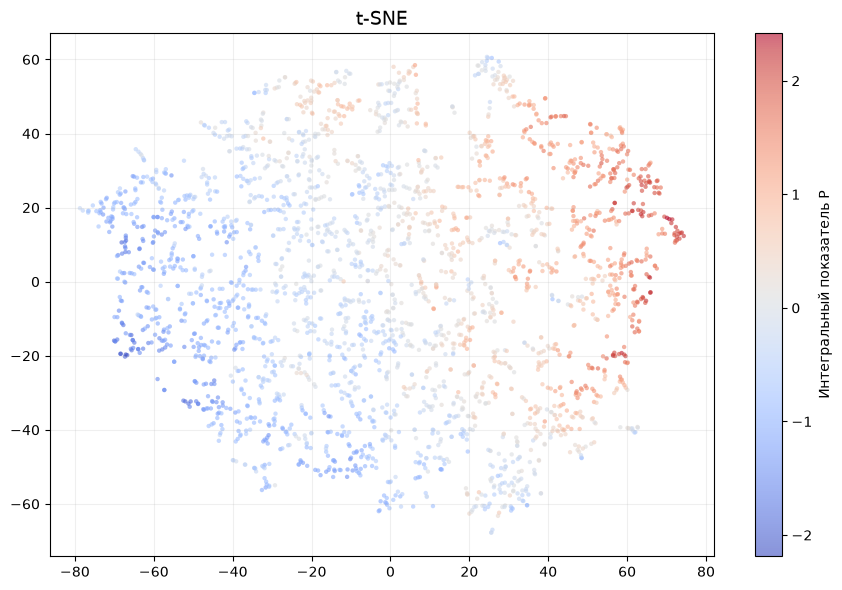

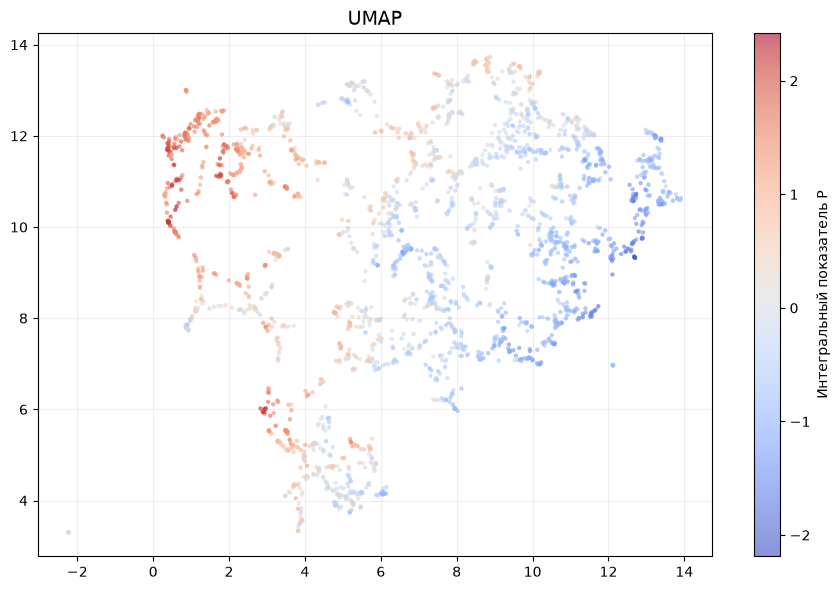

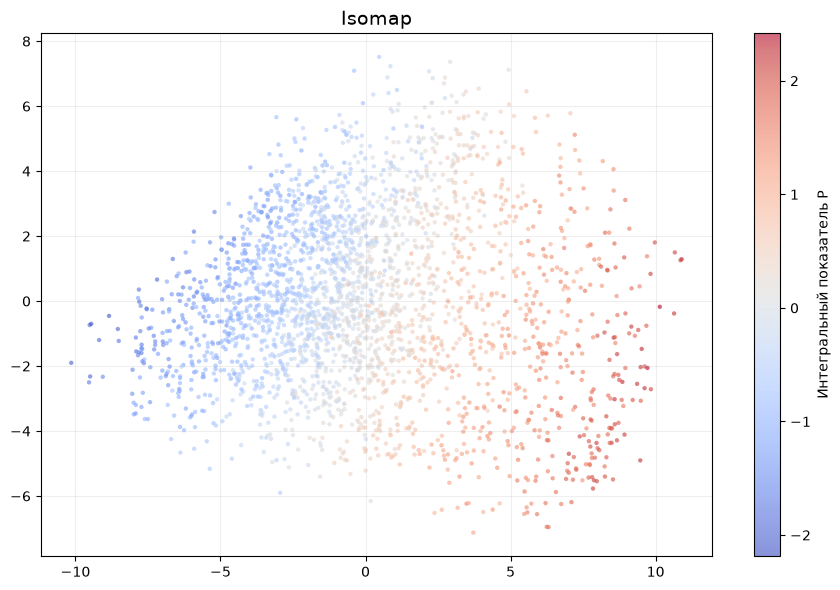

In [36]:
def build_plot(X_data, title):
    plt.figure(figsize=(9, 6))
    scatter = plt.scatter(X_data[:, 0], X_data[:, 1], c = integral_indicator, cmap = 'coolwarm', s = 10, alpha = 0.6, edgecolors = 'none')
    plt.colorbar(scatter, label = 'Интегральный показатель P')
    plt.title(title, fontsize=14)
    plt.grid(alpha = 0.2)
    plt.tight_layout()
    plt.show()

best_tsne = TSNE(n_components = 2, perplexity = 15)
coords_tsne = best_tsne.fit_transform(data)

best_umap = umap.UMAP(n_components = 2, n_neighbors = 5, min_dist = 0.0)
coords_umap = best_umap.fit_transform(data)

best_isomap = Isomap(n_components = 2, n_neighbors = 30)
coords_isomap = best_isomap.fit_transform(data)

coords_pca = pca_scores.iloc[:, :2].to_numpy()

trust_pca_2 = trustworthiness(data, pca_scores.iloc[:, :2], n_neighbors = 5)
trust_pca_6 = trustworthiness(data, pca_scores.iloc[:, :6], n_neighbors = 5)
trust_tsne = trustworthiness(data, coords_tsne, n_neighbors = 5)
trust_umap = trustworthiness(data, coords_umap, n_neighbors = 5)
trust_isomap = trustworthiness(data, coords_isomap, n_neighbors = 5)

print(f"PCA(2): {trust_pca_2}")
print(f"PCA(6): {trust_pca_6}")
print(f"t-SNE: {trust_tsne}")
print(f"Umap: {trust_umap}")
print(f"Isomap: {trust_isomap}")

build_plot(coords_pca, "PCA")
build_plot(coords_tsne, "t-SNE")
build_plot(coords_umap, "UMAP")
build_plot(coords_isomap, "Isomap")
